### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
data = pd.read_csv('data/coupons.csv')

In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
#----------------------------------------------
# First looked at the table columns to see the columns info, a total of 12684 rows and most of 
# columns seems to have non-null values.
#----------------------------------------------

#data.info(verbose = True)

#----------------------------------------------
# Looked at the total count of null values and also at the total of unique values on the string columns.
# 1. Columns car, Bar, CoffeHouse, CarryAway, RestaurantLessThan20, Restaurant20To50 have null values
#----------------------------------------------

#data.isna().sum()[data.isna().sum() > 0]

#----------------------------------------------
# To explore the number of different values in each column, we can use  and explore columns that have
# to many unique values and do a bar_coupons.value_counts('column_name') to try finding bad bar_coupons, for example 
# if the gender column has more than 2 values it would be suspect, I actully tried that command and 
# most seemed reasonable, the only one with a lot of values was occupation which has 25 values but all 
# are correct.
#----------------------------------------------

#data.nunique()

#-----------------------------------------------
# Since we have 26 columns,  and there is not a big amount of different values per column we can loop 
# through the columns and print the value counts for each column, it's a low number and we can look into 
# each individually and also find the rate of missing values which is helpful to decide what to do with 
# each column that has missing values. 
#----------------------------------------------

na_total = 0
for col in data.columns:
    print(f"\n--- {col} ---")
    print(data[col].value_counts(dropna=False))
    na_values = data[col].isna().sum()
    if(col != 'car'):  # Skip the 'car' column
        na_total += na_values
    if(na_values > 0):
        print("---------Missing values ---------")
        print(f"Missing values in {col}: {na_values}")
        print(f"Missing rate in {col}: {na_values / len(data)}")
    print("---------------")

print(f"\nTotal missing values: {na_total}")
print(f"Total missing rate: {na_total / (len(data) )}")


# CONCLUSION:
# 1. The dataset seems to be pretty organized and not a lot of missing values, below are the missing values from some of the columns that can be dropped since each of them doesn't even represent a 2%
#   a) Missing rate in Bar: 0.008
#   b) Missing rate in CoffeeHouse: 0.017
#   c) Missing rate in CarryAway: 0.011
#   d) Missing rate in RestaurantLessThan20: 0.010
#   e) Missing rate in Restaurant20To50: 0.014
#
# 2. Now in case we want to do analysis with the cars missing car information is 99% (#  Missing rate in car: 0.9914853358561968)  of them so we can't drop the rows,
#  some of the rows have no useful values ( Scooter and motorcycle, Mazda5, do not drive, crossover, Car that is too old to install Onstar). We can replace the existing data with the following rules:
#   a) If they value is Mazda5 , crossover or 'car that is too old to install Onstar' we know they have a car, so those values can be replaced with car.
#   b) For Nan I would say we can assume they have a car since this is data from people driving.   




--- destination ---
destination
No Urgent Place    6283
Home               3237
Work               3164
Name: count, dtype: int64
---------------

--- passanger ---
passanger
Alone        7305
Friend(s)    3298
Partner      1075
Kid(s)       1006
Name: count, dtype: int64
---------------

--- weather ---
weather
Sunny    10069
Snowy     1405
Rainy     1210
Name: count, dtype: int64
---------------

--- temperature ---
temperature
80    6528
55    3840
30    2316
Name: count, dtype: int64
---------------

--- time ---
time
6PM     3230
7AM     3164
10AM    2275
2PM     2009
10PM    2006
Name: count, dtype: int64
---------------

--- coupon ---
coupon
Coffee House             3996
Restaurant(<20)          2786
Carry out & Take away    2393
Bar                      2017
Restaurant(20-50)        1492
Name: count, dtype: int64
---------------

--- expiration ---
expiration
1d    7091
2h    5593
Name: count, dtype: int64
---------------

--- gender ---
gender
Female    6511
Male      6173
N

3. Decide what to do about your missing data -- drop, replace, other...

In [5]:
# IMPORTANT
# We are dropping the rows where there are missing data in regards to the number of times the customer has visited the 
# given place and the coupon type is of that specific type ( i.e. if the coupon is type Bar and the Bar column has a NaN value we drop ip, but 
# if coupon type is Bar and the CoffeeHouse column is the one with the NaN value then we don't drop it as that row is useful for Bar coupon analysis.


columns_tp_drop = ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']
indexes_to_drop = []
# Coupon Values 'Coffee House, Restaurant(<20), Carry out & Take away, Bar, Restaurant(20-50)'       
for col in columns_tp_drop:
    match col:
        case 'Bar':
            indexes_to_drop.append(data[(data[col].isna()) & (data['coupon'] =='Bar')].index.tolist()) # we only drop Bar coupon rows if the Bar column is NaN, otherwise we can keep the row as it is useful for Bar analysis
        case 'CoffeeHouse':
            indexes_to_drop.append(data[(data[col].isna()) & (data['coupon'] =='Coffee House')].index.tolist()) # same logic as bar but applied to CoffeeHouse and so forth.
        case 'CarryAway':
            indexes_to_drop.append(data[(data[col].isna()) & (data['coupon'] =='Carry out & Take away')].index.tolist())
        case 'RestaurantLessThan20':
            indexes_to_drop.append(data[(data[col].isna()) & (data['coupon'] =='Restaurant(<20)')].index.tolist())
        case 'Restaurant20To50':
            indexes_to_drop.append(data[(data[col].isna()) & (data['coupon'] =='Restaurant(20-50)')].index.tolist())

indexes_to_drop = np.concatenate(indexes_to_drop);
total_rows_before = len(data)
print(f"Total rows to drop: {len(indexes_to_drop)}")
data.drop(indexes_to_drop, inplace = True);
print(f"Dropped rate: {len(indexes_to_drop)/total_rows_before}")


# CONCLUSION:
# 1. After cleaning the missing values except the car column the dropped rate is 0.01% of the original data. Using the logic of only removing a row if the specific coupon matches the same type of column information where the column value is NaN.


#Replacing the car missing values with the rules explained on the above 
data.loc[data['car'] == 'Mazda5', 'car'] = 'car'
data.loc[data['car'] == 'crossover', 'car'] = 'car'
data.loc[data['car'] == 'Car that is too old to install Onstar :D', 'car'] = 'car'
data["car"] = data["car"].fillna('car')

data.value_counts('car')





Total rows to drop: 164
Dropped rate: 0.012929675181330811


car
car                       12476
Scooter and motorcycle       22
do not drive                 22
Name: count, dtype: int64

4. What proportion of the total observations chose to accept the coupon?



Y
1    0.56861
0    0.43139
Name: proportion, dtype: float64


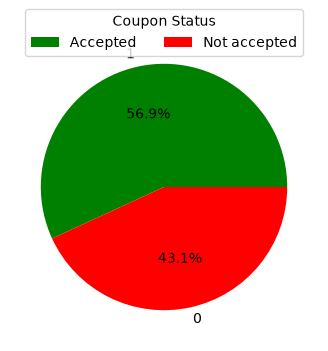

In [6]:
# We do a value_counts which returns a series with values 0 for not accepted and 1 for accepted 
counts = data["Y"].value_counts(normalize=True)
print(counts)
counts.plot.pie(
    autopct="%1.1f%%",
    figsize=(4, 4),
    colors='gr',
)

# reworking the legend to display readable values and good positioning
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(
    handles,
    ['Accepted' if x == '1' else 'Not accepted' for x in labels],
    title="Coupon Status",
    loc='upper center',
    ncol=3,
    bbox_to_anchor=(0.5, 1.1))
# CONCLUSION:
# The Acceptance proportion for all coupons is 56.9%


5. Use a bar plot to visualize the `coupon` column.

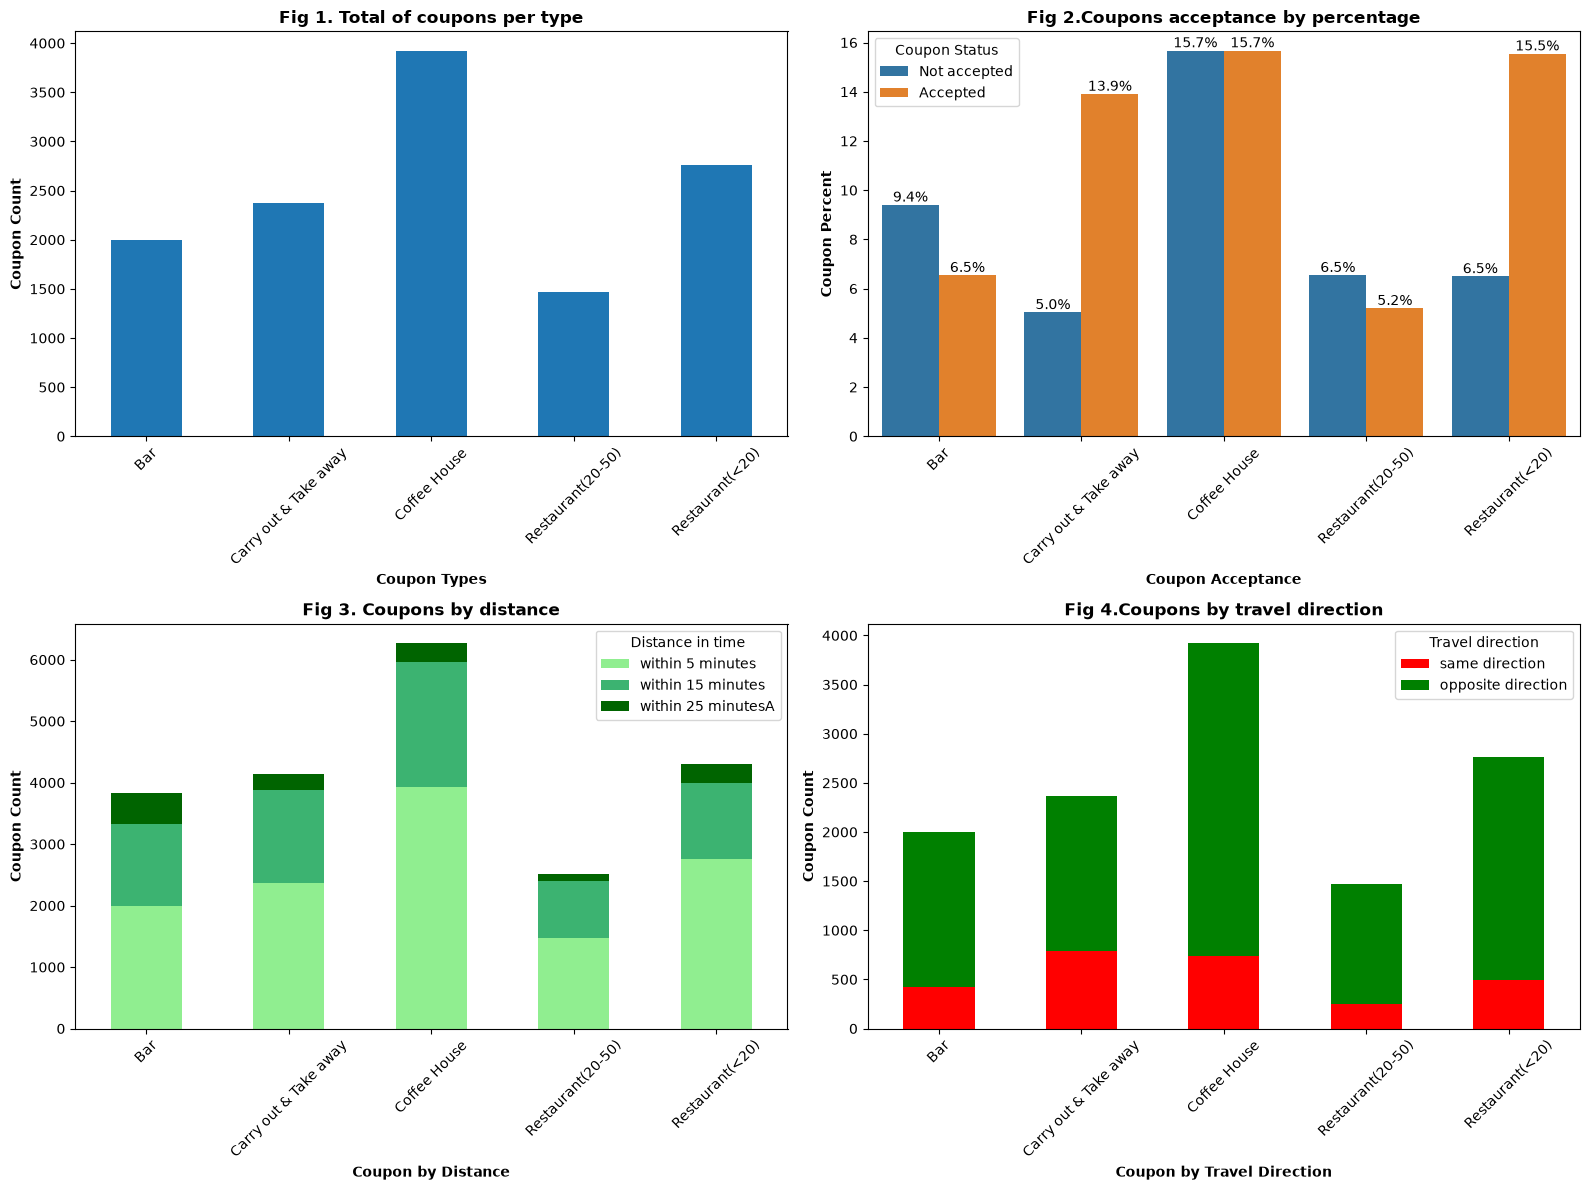

In [7]:

#Figure 1 Total of coupons per coupon type
plt.figure(figsize = (16,12))
ax1 = plt.subplot(2, 2, 1)
data["coupon"].value_counts().sort_index().plot( kind="bar", ax = ax1)
plt.tick_params(axis='x', labelrotation=45)
plt.xlabel('Coupon Types', fontweight='bold')
plt.ylabel('Coupon Count',fontweight='bold')
plt.title('Fig 1. Total of coupons per type', fontweight='bold')

#Figure 2 Coupons by percentage and acceptance
ax2 = plt.subplot(2, 2, 2)
coupon_acceptance = sns.countplot(data, x='coupon', hue='Y',  order=sorted(data["coupon"].unique()), ax=ax2, stat='percent')
plt.tick_params(axis='x', labelrotation=45)
plt.xlabel('Coupon Acceptance', fontweight='bold')
plt.ylabel('Coupon Percent',fontweight='bold')
plt.title('Fig 2.Coupons acceptance by percentage', fontweight='bold')

# reworking the legend to display readable values and good positioning
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(
    handles,
    ['Accepted' if x == '1' else 'Not accepted' for x in labels],
    title="Coupon Status")
for container in coupon_acceptance.containers:
    coupon_acceptance.bar_label(container,fmt="%.1f%%")

#Figure 3 Coupons distribution by distance
ax3 = plt.subplot(2, 2, 3)
data.groupby(['coupon']).agg(
    {'toCoupon_GEQ5min':'sum', 'toCoupon_GEQ15min':'sum', 'toCoupon_GEQ25min':'sum'}).plot(kind='bar', ax= ax3, 
    color = ['lightgreen', 'mediumseagreen', 'darkgreen'], stacked=True)
plt.tick_params(axis='x', labelrotation=45)
plt.xlabel('Coupon by Distance', fontweight='bold')
plt.ylabel('Coupon Count',fontweight='bold')
plt.title('Fig 3. Coupons by distance', fontweight='bold')
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(
    handles,
    ['within 5 minutes' if x == 'toCoupon_GEQ5min' else
     'within 15 minutes' if x == 'toCoupon_GEQ15min' else
     'within 25 minutesA'
     for x in labels],
    title="Distance in time"
)

#Figure 4 Coupons distribution by travel direction
ax4 = plt.subplot(2, 2, 4)
data.groupby(['coupon']).agg(
    {'direction_same':'sum', 'direction_opp':'sum'}).plot(kind='bar', ax=ax4, color=['red', 'green'], stacked=True)
plt.tick_params(axis='x', labelrotation=45)
plt.xlabel('Coupon by Travel Direction', fontweight='bold')
plt.ylabel('Coupon Count',fontweight='bold')
plt.title('Fig 4.Coupons by travel direction', fontweight='bold')
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, 
    ['same direction' if x == 'direction_same' else 'opposite direction' for x in labels],
    title="Travel direction")

plt.tight_layout()

# CONCLUSION:
#Here are some insighs related to the coupons in general, first two is by providing the coupons itself and the third and fourth are related to distance and travel direction
#1. The coupons amount was not equally distributed, the 'Coffe House' was the most distributed coupons and 'Restaurant(20-50)' where the least (Fig 1.) 
#2. Acceptance between each type of coupons was also widely different, 'Coffe House' was equally accepted and rejected, Bar had the worse acceptance proportion while 'Carry out & Take away' had the best.(Fig 2.)
#3. Coupons had a greater distribution and better correlated to the closer the driver was to the business offering it.
#4. Coupons were mostly distributed in the opposite travel direction where the driver was going.


6. Use a histogram to visualize the temperature column.

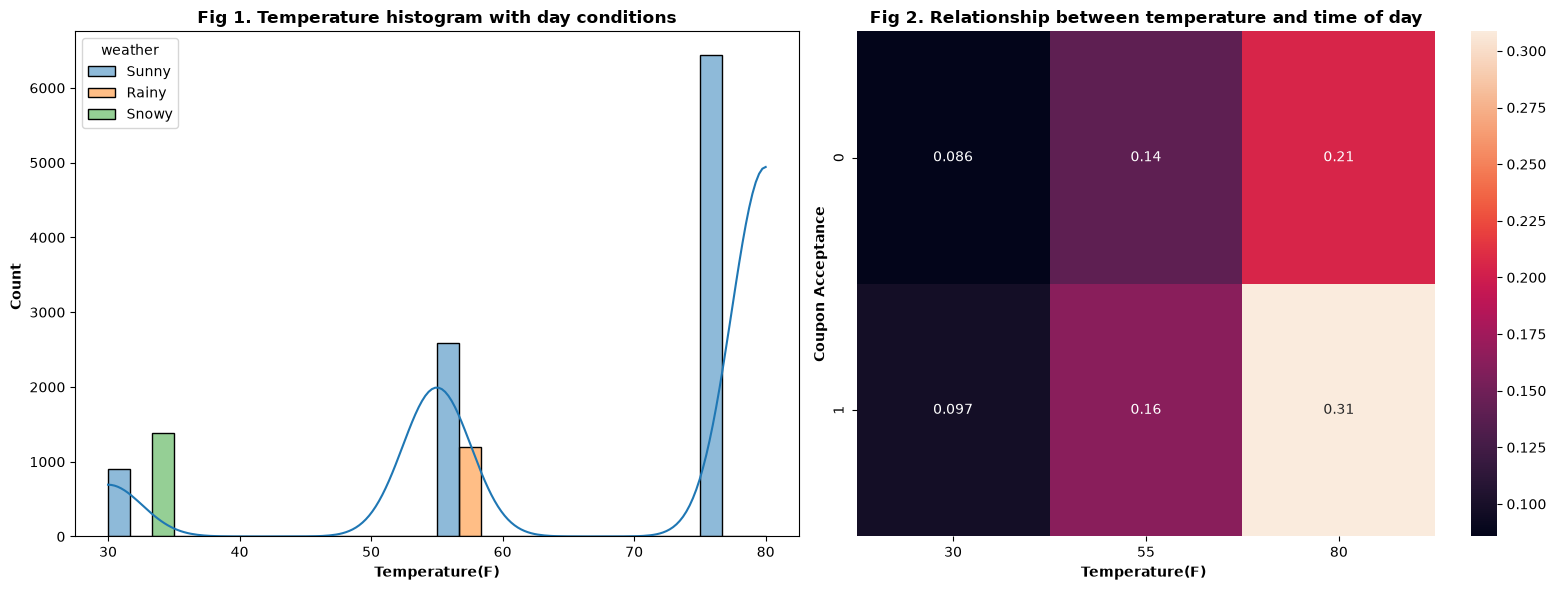

In [8]:
#Figure 1 Temperature histogram using the weather by weather conditions 
plt.figure(figsize = (16,6))
plt.subplot(121)
sns.histplot(data=data, x='temperature', hue='weather', multiple='dodge', bins=10, kde=True)
plt.ylabel('Count ', fontweight='bold')
plt.xlabel('Temperature(F)',fontweight='bold')
plt.title('Fig 1. Temperature histogram with day conditions', fontweight='bold')
plt.subplot(122)

#Figure 1 Temperature relationship to coupon acceptance
sns.heatmap(pd.crosstab(data.Y, data.temperature, normalize=True), annot=True)
plt.xlabel('Temperature(F) ', fontweight='bold')
plt.ylabel('Coupon Acceptance',fontweight='bold')
plt.title('Fig 2. Relationship between temperature and time of day', fontweight='bold')

plt.tight_layout()


# CONCLUSION:
#Here are some insighs related to the coupons in general, first two is by providing the coupons itself and the third and fourth are related to distance and travel direction
#1. Most of the coupons were distributed in the with temperatures close to 80 degreesso the data is left skewed to high temperatures so they were probably out of the winter season (Fig 1.)
#2. It seems like coupons are more accepted the more hotter the temperature is, which make sense as people are more likely to go out when there is better weather in general, and based on Fig.1 
#   on the days or higher temperatures it was more sunny as well.
 



**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [9]:
# Using the previous cleaned dataframe contains already the maximum amount of bar coupons where we have also the information about the number of times the person has visited a bar
bar_coupons = data.query("coupon == 'Bar'")
len(bar_coupons)

1996

2. What proportion of bar coupons were accepted?


Y
0    0.589679
1    0.410321
Name: proportion, dtype: float64


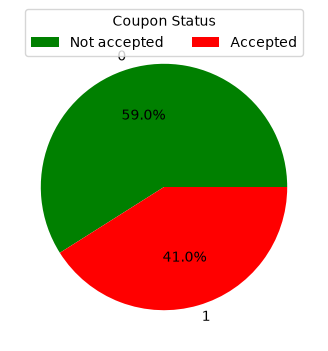

In [10]:
# We do a value_counts which returns a series with values 0 for not accepted and 1 for accepted 

bar_counts = bar_coupons["Y"].value_counts(normalize=True)
print(bar_counts)

bar_counts.plot.pie(
    autopct="%1.1f%%",
    figsize=(4, 4),
    colors='gr'
)

# reworking the legend to display readable values and good positioning
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(
    handles,
    ['Accepted' if x == '1' else 'Not accepted' for x in labels],
    title="Coupon Status",
    loc='upper center',
    ncol=3,
    bbox_to_anchor=(0.5, 1.1))

# CONCLUSION:
# The Acceptance proportion for bar coupons is 41.0%


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


Population that went 3 or fewer times : 1797
Population that went 3 or fewer times (accepting) : 666
Population that went 3 or more times : 199
Population that went 3 or more times (accepting) : 153


C:\Users\kAdministrator\AppData\Local\Temp\ipykernel_42732\1852857129.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot3 = sns.barplot(


Text(0.5, 1.0, 'Bar coupon acceptance percent by frequency')

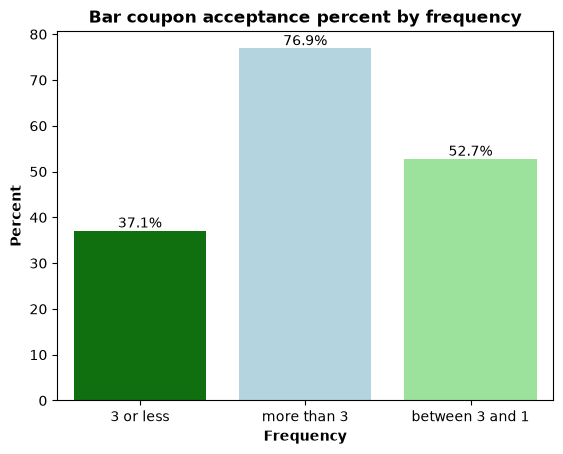

In [11]:
# we might usethe bar attendance in multiple analisys, since they are an ordered categorical values I'm going to add an extra column bar_attendance where 
# never = 0, less1 = 1, 1~3 = 3, 4~8 = 8, gt8 = 9  , again this is categorical data can be ordered and it make sense, otherwise I won't be assigning number to label values.

bar_attendance_bounds = {
    'never': 0,
    'less1': 1,
    '1~3': 3,
    '4~8': 8,
    'gt8': 9
}
# create the new column which includes a numeric value for the bar attendance
bar_coupons['bar_attendance'] = bar_coupons['Bar'].map(lambda x: bar_attendance_bounds[x])

#total of bar attendance per criteria
population_3less = bar_coupons.query("bar_attendance <= 3 ").shape[0]
population_3more = bar_coupons.query("bar_attendance > 3").shape[0]

#total of bar attendance per criteria and coupon being accepted
population_3or_less_accepting = bar_coupons.query("bar_attendance <= 3 and Y == 1").shape[0]
population_3or_more_accepting = bar_coupons.query("bar_attendance > 3 and Y == 1").shape[0]

#calculate the rate
rate_3or_less = ( population_3or_less_accepting / population_3less) * 100
rate_3or_more = (population_3or_more_accepting / population_3more) * 100

#now this is a special case probably for bars, if customers have said they have never gone to a bar it is very likely they are going to reject the coupon 
#as they might not drink alcohol at all. This calculation is just added to see how those customers affect the meassurements
population_between_1_and_3 = bar_coupons.query("bar_attendance <= 3 and  bar_attendance > 0").shape[0]
population_between_1_and_3_accepting = bar_coupons.query("bar_attendance <= 3 and  bar_attendance > 0 and Y == 1").shape[0]
rate_between_1_and_3_accepting = (population_between_1_and_3_accepting / population_between_1_and_3) * 100

print(f"Population that went 3 or fewer times : {population_3less}")
print(f"Population that went 3 or fewer times (accepting) : {population_3or_less_accepting}")
print(f"Population that went 3 or more times : {population_3more}")
print(f"Population that went 3 or more times (accepting) : {population_3or_more_accepting}")




plot_data3 = pd.DataFrame({
    "Type": ["3 or less", "more than 3", "between 3 and 1"],
    "Rate": [rate_3or_less, rate_3or_more, rate_between_1_and_3_accepting]
})

plot3 = sns.barplot(
    data=plot_data3,
    x="Type",
    y="Rate",
    palette=["green","lightblue", "lightgreen"]
)
for container in plot3.containers:
    plot3.bar_label(container, fmt="%.1f%%")

plt.xlabel('Frequency', fontweight='bold')
plt.ylabel('Percent',fontweight='bold')
plt.title('Bar coupon acceptance percent by frequency',fontweight='bold')

# CONCLUSION:
# When including in bar coupons calculations conditions that required a frequency less that a certain number it might be worth excluding customer who had never gone to a bar
# as it shows in the figure the 3rd bar is the same meassumernt as the first one ( less than 3 times per month) but excluding those who has never gone to a bar

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


Population that falls under the two condition : 420
Population that falls under the two condition (accepting): 292
All other population : 1576
All other population (accepting): 527


C:\Users\kAdministrator\AppData\Local\Temp\ipykernel_42732\2510745301.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot4 = sns.barplot(


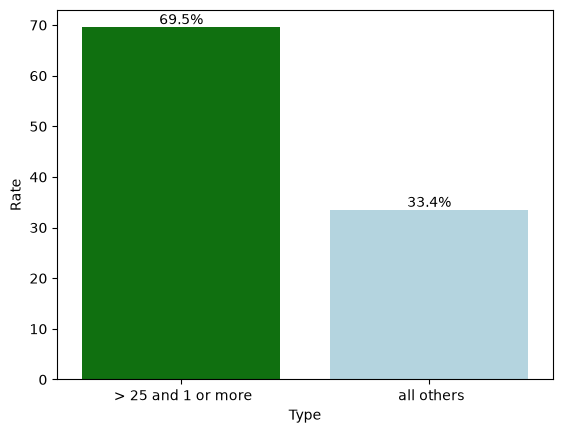

In [12]:
# ** IMPORTANT** 
# 1. Meaning of "all the others" , I'm assuming it implies negating both, original = ( go to the bar more than once and are over 25) then the all others = ~(original)  
#using a different way to query the data 

original_all4 = bar_coupons.loc[(bar_coupons['bar_attendance'] > 1) & (~bar_coupons['age'].isin(['below21','21']))].shape[0]
allothers_all4 = bar_coupons.loc[~((bar_coupons['bar_attendance'] > 1) & (~bar_coupons['age'].isin(['below21','21'])))].shape[0]

original_acceptance4 = bar_coupons.loc[(bar_coupons['bar_attendance'] > 1) & (~bar_coupons['age'].isin(['below21','21'])) & (bar_coupons['Y'] == 1)].shape[0]
allothers_acceptance4 = bar_coupons.loc[(~((bar_coupons['bar_attendance'] > 1) & (~bar_coupons['age'].isin(['below21','21'])))) & (bar_coupons['Y'] == 1)].shape[0]


original_acceptance_rate4 = (original_acceptance4 / original_all4) * 100
allothers_acceptance_rate4 = (allothers_acceptance4 / allothers_all4) * 100

print(f"Population that falls under the two condition : {original_all4}")
print(f"Population that falls under the two condition (accepting): {original_acceptance4}")
print(f"All other population : {allothers_all4}")
print(f"All other population (accepting): {allothers_acceptance4}")


plot_data4 = pd.DataFrame({
    "Type": [" > 25 and 1 or more", " all others"],
    "Rate": [original_acceptance_rate4, allothers_acceptance_rate4]
})

plot4 = sns.barplot(
    data=plot_data4,
    x="Type",
    y="Rate",
    palette=["green","lightblue"]
)
for container in plot4.containers:
    plot4.bar_label(container, fmt="%.1f%%")


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


Population that falls under the  condition : 551
Population that falls under the  condition acceptance : 393
All other population : 1445
All other population acceptance: 426


C:\Users\kAdministrator\AppData\Local\Temp\ipykernel_42732\1353592483.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot5 = sns.barplot(


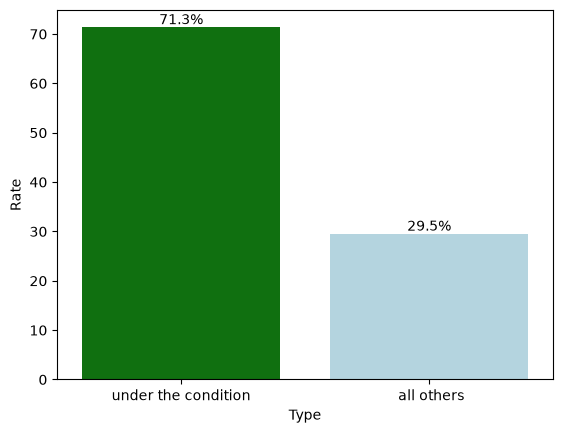

In [13]:
# ** IMPORTANT** 
# 1. When looking into the occupations value_counts there is a 'Farming Fishing & Forestry'

original_all5 = bar_coupons.query("bar_attendance > 1 and passanger != 'Kid(s)' and occupation != 'Farming Fishing & Forestry'").shape[0]
allothers_all5 = bar_coupons.query("~( bar_attendance > 1 and passanger != 'Kid(s)' and occupation != 'Farming Fishing & Forestry')").shape[0]

original_acceptance5 = bar_coupons.query("bar_attendance > 1 and passanger != 'Kid(s)' and occupation != 'Farming Fishing & Forestry' and Y == 1").shape[0]
allothers_acceptance5 = bar_coupons.query("(~(bar_attendance > 1 and passanger != 'Kid(s)' and occupation != 'Farming Fishing & Forestry')) and Y == 1").shape[0]

original_acceptance_rate5 = (original_acceptance5 / original_all5) * 100
allothers_acceptance_rate5 = (allothers_acceptance5 / allothers_all5) * 100

print(f"Population that falls under the  condition : {original_all5}")
print(f"Population that falls under the  condition acceptance : {original_acceptance5}")
print(f"All other population : {allothers_all5}")
print(f"All other population acceptance: {allothers_acceptance5}")

plot_data5 = pd.DataFrame({
    "Type": ["under the condition", " all others"],
    "Rate": [original_acceptance_rate5, allothers_acceptance_rate5]
})

plot5 = sns.barplot(
    data=plot_data5,
    x="Type",
    y="Rate",
    palette=["green","lightblue"]
)
for container in plot5.containers:
    plot5.bar_label(container, fmt="%.1f%%")



6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



Population that falls under the  condition : 771
Population that falls under the  condition acceptance : 616
All other population : 1225
All other population acceptance: 363


C:\Users\kAdministrator\AppData\Local\Temp\ipykernel_42732\1087430842.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot6 = sns.barplot(


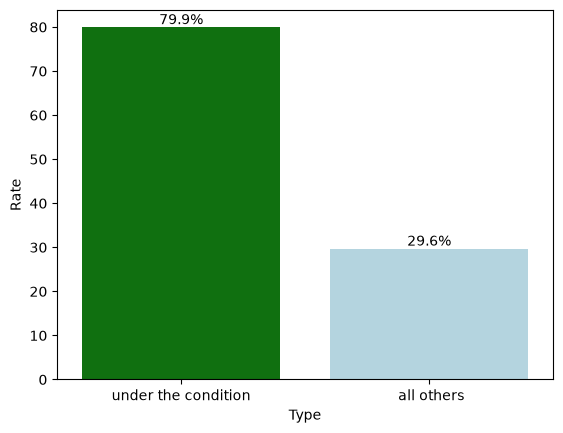

In [14]:
# I found dividing the conditions is an easy way to get data quick as you can add or remove some of them to see which one could influence more the results
condition1 = "bar_attendance > 1 and passanger != 'Kid(s)' and maritalStatus != 'Widowed'"
condition2 = "bar_attendance > 1 and age in ('below21','21','26')"
condition3 = "RestaurantLessThan20 in ('4~8','gt8') and income in('Less than $12500', '$12500 - $24999','$25000 - $37499','$37500 - $49999')"
fullCondition = f"({condition1}) or ({condition2}) or ({condition3})"

original_all6 = bar_coupons.query(f"{fullCondition}").shape[0]
allothers_all6 = bar_coupons.query(f"~({fullCondition})").shape[0]


original_acceptance6 = bar_coupons.query(f"{fullCondition} and Y == 1").shape[0]
allothers_acceptance6 = bar_coupons.query(f"(~({fullCondition})) and Y == 1").shape[0]

original_acceptance_rate6 = (original_acceptance6 / original_all6) * 100
allothers_acceptance_rate6 = (allothers_acceptance6 / allothers_all6) * 100


print(f"Population that falls under the  condition : {original_all6}")
print(f"Population that falls under the  condition acceptance : {original_acceptance6}")
print(f"All other population : {allothers_all6}")
print(f"All other population acceptance: {allothers_acceptance6}")

plot_data6 = pd.DataFrame({
    "Type": ["under the condition", " all others"],
    "Rate": [original_acceptance_rate6, allothers_acceptance_rate6]
})

plot6 = sns.barplot(
    data=plot_data6,
    x="Type",
    y="Rate",
    palette=["green","lightblue"]
)
for container in plot6.containers:
    plot6.bar_label(container, fmt="%.1f%%")


#bar_coupons.columns


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

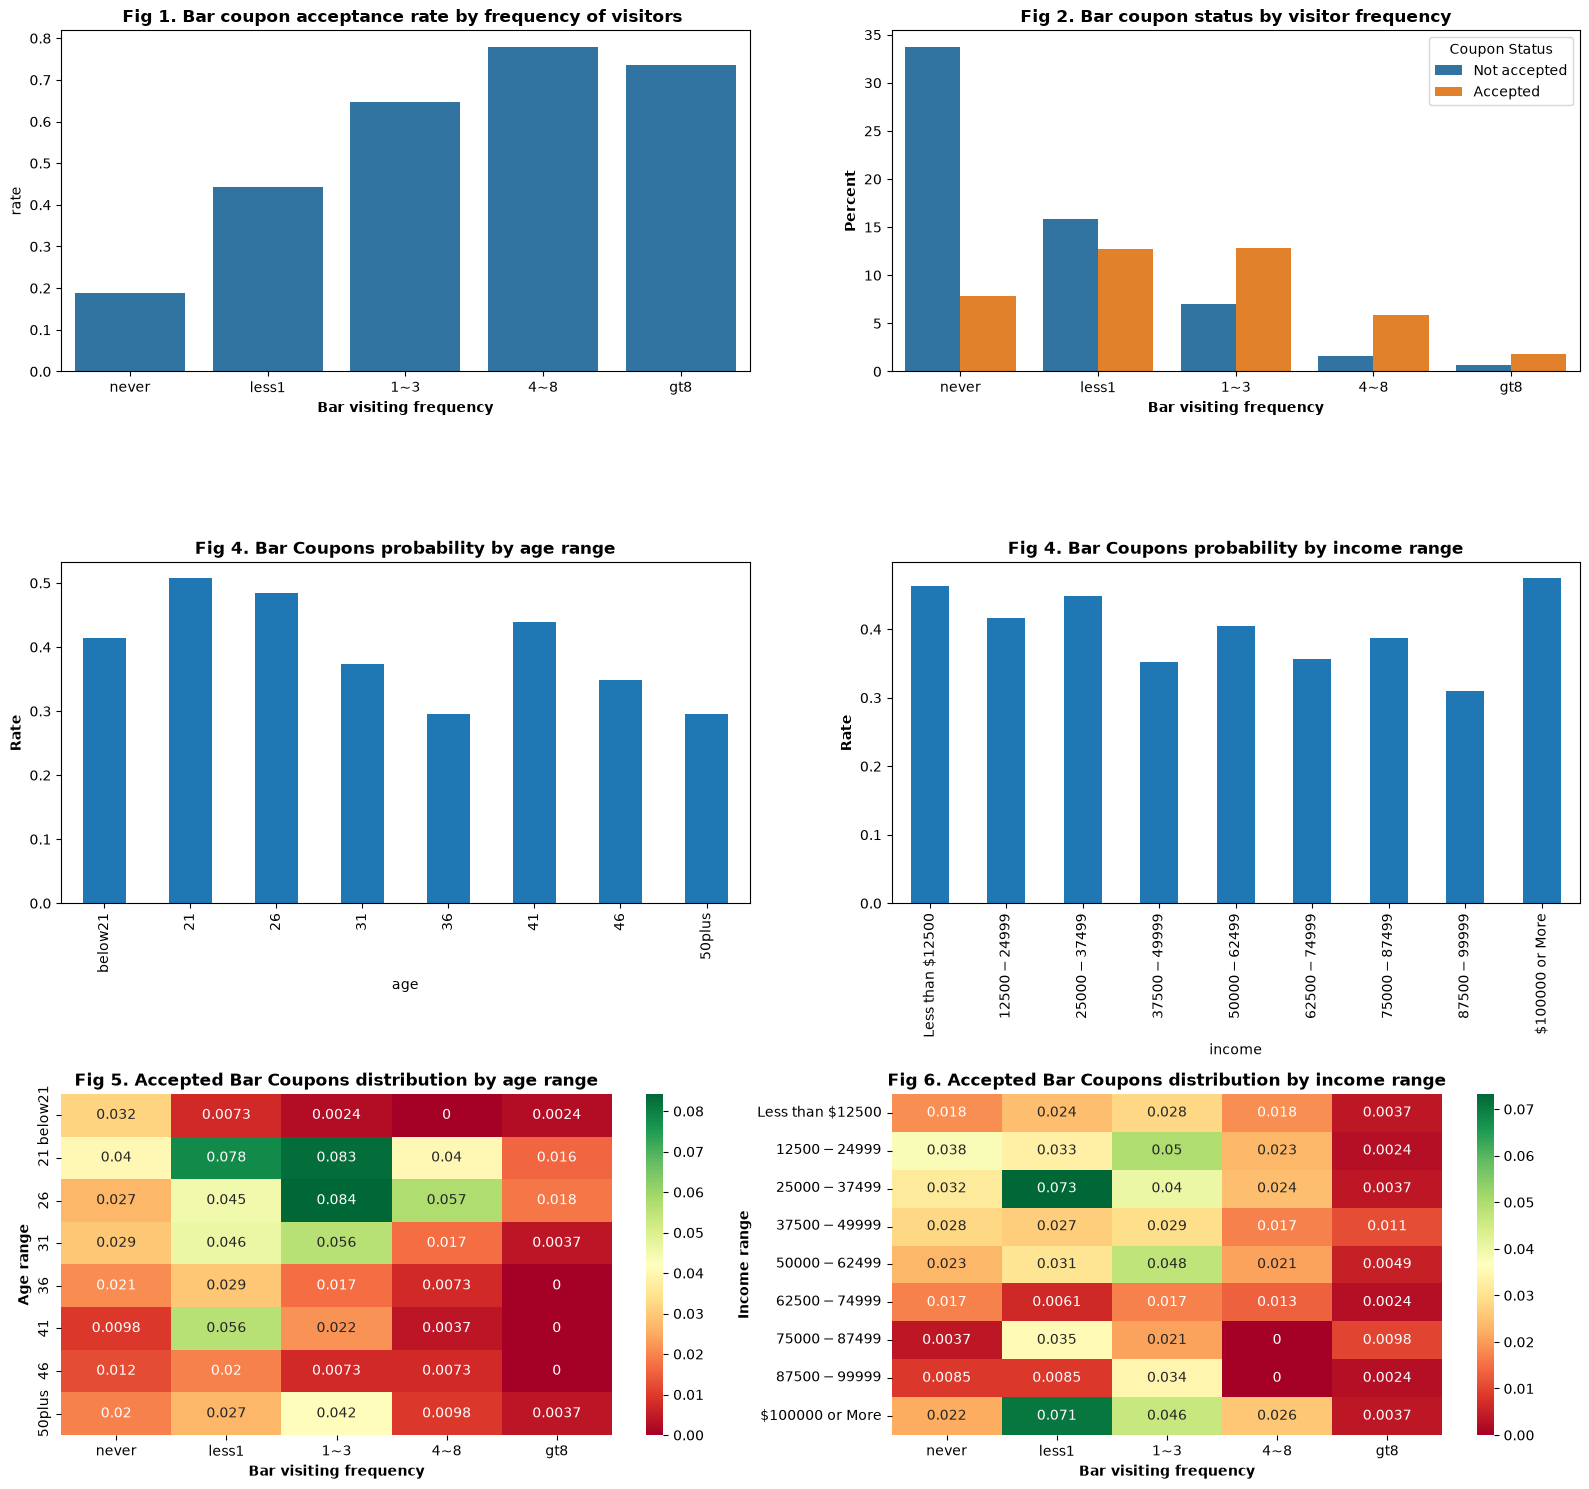

In [15]:

bar_order = ["never", "less1", "1~3", "4~8", "gt8", ]
bar_coupons["Bar"] = pd.Categorical(bar_coupons["Bar"], categories=bar_order, ordered=True)
bar_coupons.sort_values("Bar")

age_order = ["below21", "21", "26", "31", "36", "41", "46", "50plus" ]
bar_coupons["age"] = pd.Categorical(bar_coupons["age"], categories=age_order, ordered=True)
bar_coupons.sort_values("age")

income_order = ["Less than $12500", "$12500 - $24999", "$25000 - $37499", "$37500 - $49999", "$50000 - $62499", "$62500 - $74999", "$75000 - $87499", "$87500 - $99999", "$100000 or More" ]
bar_coupons["income"] = pd.Categorical(bar_coupons["income"], categories=income_order, ordered=True)
bar_coupons.sort_values("income")

plt.figure(figsize = (16,15))
ax1 = plt.subplot(3, 2, 1)

#Fig 1. Bar coupon acceptance proportion by frequency of the visitors
relationship = pd.crosstab(bar_coupons.Bar, bar_coupons.Y )
relationship['rate'] = relationship[1] / (relationship[0] + relationship[1])
sns.barplot(relationship,x=relationship.index, y='rate', ax = ax1)
plt.xlabel('Acceptance rate', fontweight='bold')
plt.xlabel('Bar visiting frequency',fontweight='bold')
plt.title('Fig 1. Bar coupon acceptance rate by frequency of visitors ', fontweight='bold')

#Fig 2. Bar coupon status by visitor frecuency
ax2 = plt.subplot(3, 2, 2)
sns.countplot(bar_coupons, x = 'Bar', hue='Y', stat='percent', ax=ax2)
plt.xlabel('Bar visiting frequency', fontweight='bold')
plt.ylabel('Percent',fontweight='bold')
plt.title('Fig 2. Bar coupon status by visitor frequency', fontweight='bold')
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(
    handles,
    ['Accepted' if x == '1' else 'Not accepted' for x in labels],
    title="Coupon Status")
    

#Fig 3. Bar Coupons probability by age range
ax3 = plt.subplot(3, 2, 3)
bar_coupons.groupby("age")["Y"].mean().plot(ax=ax3, kind='bar')
plt.ylabel('Rate', fontweight='bold')
plt.title('Fig 4. Bar Coupons probability by age range', fontweight='bold')

#Fig 4. Bar Coupons probability by income range
ax4 = plt.subplot(3, 2, 4)
bar_coupons.groupby("income")["Y"] .mean().plot(ax=ax4, kind='bar')
plt.ylabel('Rate', fontweight='bold')
plt.title('Fig 4. Bar Coupons probability by income range', fontweight='bold')

#Fig 5. Accepted Bar Coupons distribution by age range
ax5 = plt.subplot(3, 2, 5)
acceptedCouponsByAge = bar_coupons.query('Y == 1')[['age','Bar']]
sns.heatmap(pd.crosstab(acceptedCouponsByAge.age, acceptedCouponsByAge.Bar, normalize=True), annot=True, ax = ax5, cmap = "RdYlGn")
plt.xlabel('Bar visiting frequency', fontweight='bold')
plt.ylabel('Age range',fontweight='bold')
plt.title('Fig 5. Accepted Bar Coupons distribution by age range', fontweight='bold')

#Fig 6. Bar Coupons distribution by income range
ax6 = plt.subplot(3, 2, 6)
acceptedCouponsByIncome = bar_coupons.query('Y == 1')[['income','Bar']]
sns.heatmap(pd.crosstab(acceptedCouponsByIncome.income, acceptedCouponsByIncome.Bar, normalize=True), annot=True, ax = ax6, cmap = "RdYlGn")
plt.xlabel('Bar visiting frequency', fontweight='bold')
plt.ylabel('Income range',fontweight='bold')
plt.title('Fig 6. Accepted Bar Coupons distribution by income range', fontweight='bold')


plt.tight_layout()

# CONCLUSION 1:
# After loking at the bar coupons we can notice some behaviors
# 1. The more the visitors go to the bar per month the more they use coupons (Fig 1), the denial rate decreases significangly among regular bar visitors (Fig 2).
# 2. Seems some small number of persons who has never visited a bar were inclined to go to one because they got a coupon and accepted it (Fig 1 and Fig 2). It is worth noting that still the majority 
#   of the person who has never visited a bar still rejected the coupon. As mentioned earlier this number can tweak some of the statistics if trying to count low frequency visitors and including the non-visitors.
# 3. Based on age range seems like the people between 21 and 30 years are more likely to use the coupons (Fig 3)
# 4. Based on income range seems like low earners  groups under $37500 tend to accept the coupon more but also the top income earners ( $100000 or more) as well (Fig 3)
# 5. Among drivers who accepted the coupons people between 21 and 30 visit more bars and with a frequency of up to 4 to 8 times per month, the higher concentration is noticed around 3 times per month though.(Fig 3)
# 6. Among drivers who accepted the coupons people in income brakets making around or under $37500 are more likely to use the coupon around 1 time per month and the same thing happens with earners making over $100000
# 7. Generally the age and income groups who are more likely to accept the coupons  and those same groups peak visitng bars 3 times or less per month.



### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

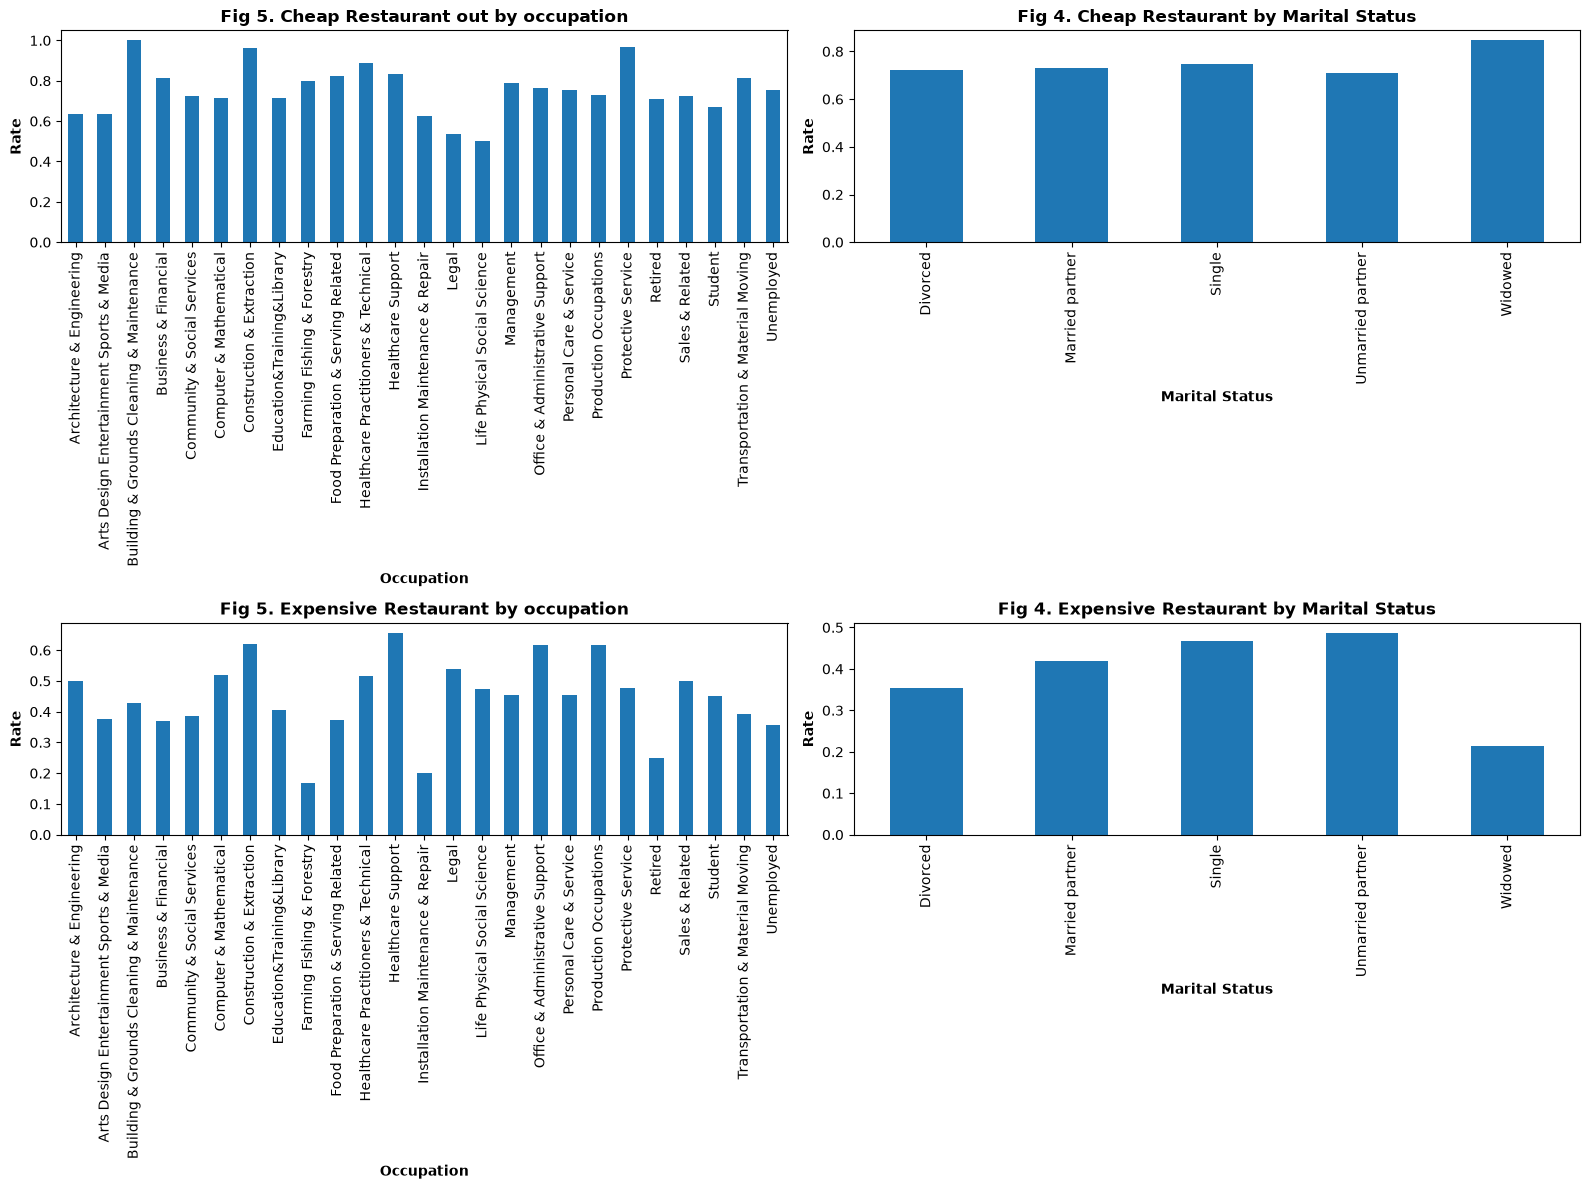

In [16]:
carryout_coupons = data.query("coupon == 'Carry out & Take away'")

plt.figure(figsize = (16,12))

#Figure 1 Coupons distribution by travel direction
ax1 = plt.subplot(2, 2, 1)
carryout_coupons.groupby("occupation")["Y"].mean().plot(ax=ax1, kind='bar')
plt.ylabel('Rate', fontweight='bold')
plt.xlabel('Occupation', fontweight='bold')
plt.title('Fig 5. Cheap Restaurant out by occupation', fontweight='bold')


#Figure 5 Coupons distribution by travel direction
ax2 = plt.subplot(2, 2, 2)
carryout_coupons.groupby("maritalStatus")["Y"].mean().plot(ax=ax2, kind='bar')
plt.ylabel('Rate', fontweight='bold')
plt.xlabel('Marital Status', fontweight='bold')
plt.title('Fig 4. Cheap Restaurant by Marital Status', fontweight='bold')


cheap_restaurant = data.query("coupon == 'Restaurant(20-50)'")

#Figure 5 Coupons distribution by travel direction
ax3 = plt.subplot(2, 2, 3)
cheap_restaurant.groupby("occupation")["Y"].mean().plot(ax=ax3, kind='bar')
plt.ylabel('Rate', fontweight='bold')
plt.xlabel('Occupation', fontweight='bold')
plt.title('Fig 5. Expensive Restaurant by occupation', fontweight='bold')


#Figure 5 Coupons distribution by travel direction
ax4 = plt.subplot(2, 2, 4)
cheap_restaurant.groupby("maritalStatus")["Y"].mean().plot(ax=ax4, kind='bar')
plt.ylabel('Rate', fontweight='bold')
plt.xlabel('Marital Status', fontweight='bold')
plt.title('Fig 4. Expensive Restaurant by Marital Status', fontweight='bold')

plt.tight_layout()


# CONCLUSION:
# Here is some differentiating data between cheap and expensive restaurants
# 1. Cleaning & Maintenance, Construction and Protective server workers are more likely to accept cheap restaurants coupons
# 2. Construction, Health care , Office & Administrative and Production occupations are more likely to accept expensive restaurants coupons
# 3. Windowed are more likely to accept cheap restaurants coupons.
# 4. Singles and Unmarried partners are more likely to accept expensive restaurants coupons


